# Two-Sample T-Test and the Impact of Sample Size

### 1. The Two-Sample T-Test
- A **two-sample t-test** checks whether the means of two independent groups differ, for example the average spending of customers who saw two different marketing campaigns.
- **Null hypothesis (H0):** the population mean spending is the same in Group A and Group B (μA = μB).
- **Alternative hypothesis (H1):** the population means differ (μA ≠ μB).
- **Test statistic:** the t-statistic is the difference between the two sample means divided by its standard error. The larger it is (in absolute value), the bigger the gap relative to the noise in the data.
- **p-value:** the probability, if H0 were true, of seeing a difference in sample means at least as large as the one we observed. A small p-value (below 0.05 by convention) means the observed difference would be unusual under H0, so we reject H0.

**Assumptions**
- The two groups are independent of each other.
- The data in each group is roughly normal. This matters mostly for small samples; with large samples the t-test holds up well under mild non-normality.
- The classic (Student's) t-test also assumes the two groups have similar variances. **Welch's t-test** (`equal_var=False` in scipy) drops that assumption and is the safer default, so we use it throughout.

**Limitations**
- It compares means only, not the spread or shape of the distributions.
- Outliers can pull the mean and distort the result.
- With very large samples, even a tiny difference becomes statistically significant, whether or not it matters in practice.

### 2. Synthetic Data: Two Marketing Campaigns
We simulate the spending of 1,000 customers per campaign. Campaign A has a slightly higher average and a wider spread.

In [1]:
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind, shapiro
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

from IPython.display import Pretty as disp
hint = 'https://raw.githubusercontent.com/soltaniehha/Intro-to-Data-Analytics/main/docs/hints/'  # path to hints on GitHub

rng = np.random.default_rng(149)

total_size = 1000
# Group A: Marketing Campaign A - slightly higher spending
group_a = rng.normal(loc=150, scale=35, size=total_size)  # loc: center (average), scale: standard deviation (spread)

# Group B: Marketing Campaign B - lower spending
group_b = rng.normal(loc=140, scale=25, size=total_size)

# Create DataFrame
data = pd.DataFrame({
    'group': ['A']*total_size + ['B']*total_size,
    'spending': np.concatenate([group_a, group_b])
    })
data

,group,spending
0,A,208.548471
1,A,146.879399
2,A,124.445245
3,A,185.290670
4,A,133.531183
...,...,...
1995,B,92.858642
1996,B,136.404104
1997,B,97.246540
1998,B,151.777542


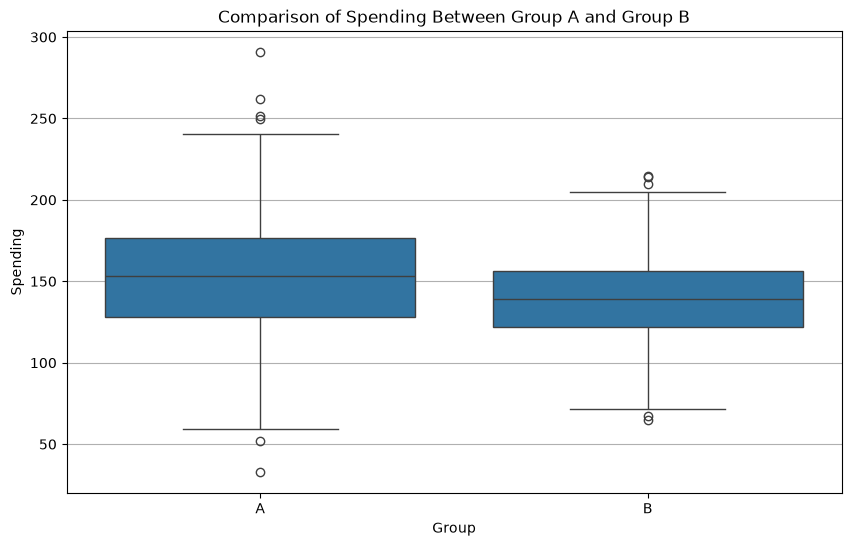

In [2]:
# Box plot to compare the groups
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(x='group', y='spending', data=data, ax=ax)
ax.set_title('Comparison of Spending Between Group A and Group B')
ax.set_xlabel('Group')
ax.set_ylabel('Spending')
ax.grid(True, axis='y');

#### Checking Normality
The **Shapiro-Wilk test** has H0 "the data are normally distributed." A p-value above 0.05 means we have no evidence against normality. We run it on a random subsample of 50, since on very large samples it flags even tiny, harmless departures from normality.

In [3]:
sub_a = rng.choice(group_a, size=50, replace=False)
sub_b = rng.choice(group_b, size=50, replace=False)
shapiro_a = shapiro(sub_a)
shapiro_b = shapiro(sub_b)

print(f"Group A: W-statistic={shapiro_a.statistic:.4f}, p-value={shapiro_a.pvalue:.4f}")
print(f"Group B: W-statistic={shapiro_b.statistic:.4f}, p-value={shapiro_b.pvalue:.4f}")
if shapiro_a.pvalue > 0.05 and shapiro_b.pvalue > 0.05:
    print("No evidence against normality in either group.")
else:
    print("At least one group looks non-normal.")

Group A: W-statistic=0.9835, p-value=0.7059
Group B: W-statistic=0.9673, p-value=0.1793
No evidence against normality in either group.


### 3. Sample Size and Its Impact
- Larger samples shrink the standard error of the sample mean, which makes a real difference easier to detect.
- Below we draw random samples of increasing size from each group and run a t-test on each pair.
- Each point is one random sample, so the curve is noisy. Re-run the cell a few times.

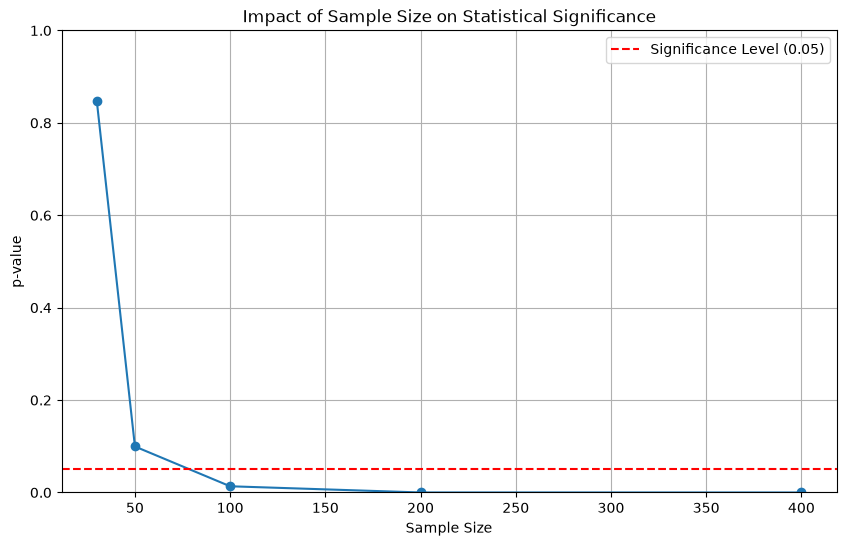

Sample Size: 30, p-value: 0.8466
	- No significant difference at this sample size.
Sample Size: 50, p-value: 0.0996
	- No significant difference at this sample size.
Sample Size: 100, p-value: 0.0135
	- Significant difference between Group A and Group B spending.
Sample Size: 200, p-value: 0.0001
	- Significant difference between Group A and Group B spending.
Sample Size: 400, p-value: 0.0000
	- Significant difference between Group A and Group B spending.


In [4]:
# Draw a random sample of each group and run a two-sample t-test
def perform_t_test(sample_size):
    sample_a = rng.choice(group_a, size=sample_size, replace=False)
    sample_b = rng.choice(group_b, size=sample_size, replace=False)
    t_stat, p_value = ttest_ind(sample_a, sample_b, alternative='two-sided', equal_var=False)
    return t_stat, p_value

sample_sizes = [30, 50, 100, 200, 400]
p_values = []

for size in sample_sizes:
    _, p_value = perform_t_test(size)
    p_values.append(p_value)

# Plot p-values against sample sizes
plt.figure(figsize=(10, 6))
plt.plot(sample_sizes, p_values, marker='o')
plt.axhline(y=0.05, color='r', linestyle='--', label='Significance Level (0.05)')
plt.xlabel('Sample Size')
plt.ylabel('p-value')
plt.ylim(0, 1)
plt.title('Impact of Sample Size on Statistical Significance')
plt.legend()
plt.grid(True)
plt.show()

for size, p_value in zip(sample_sizes, p_values):
    print(f"Sample Size: {size}, p-value: {p_value:.4f}")
    if p_value < 0.05:
        print("\t- Significant difference between Group A and Group B spending.")
    else:
        print("\t- No significant difference at this sample size.")

`ttest_ind()` from `scipy` compares the means of two independent samples. Setting `equal_var=False` runs Welch's t-test, which does not assume the two groups have equal variances. Real data often have different variances (here, 35 vs. 25), so this is the safer choice.

### 3.1 Two-Tailed vs. One-Tailed Tests
How we phrase the alternative hypothesis changes the test:
- A **two-tailed test** asks whether the means differ in either direction. A significant result tells us they differ, but not which one is higher.
- A **one-tailed test** asks about one direction only, for example whether Group A is higher than Group B.

#### Example 1: Two-Tailed Test
- **H0:** μA = μB
- **H1:** μA ≠ μB
- `alternative='two-sided'` is the default in `ttest_ind()`.

In [5]:
# Draw one sample of 100 per group and use it for all three tests
sample_a = rng.choice(group_a, size=100, replace=False)
sample_b = rng.choice(group_b, size=100, replace=False)

t_stat, p_value = ttest_ind(sample_a, sample_b, alternative='two-sided', equal_var=False)

print(f"Two-Tailed Test: t-statistic = {t_stat:.4f}, p-value = {p_value:.4f}")
if p_value < 0.05:
    print("There is a significant difference between Group A and Group B.")
else:
    print("No significant difference between Group A and Group B.")

Two-Tailed Test: t-statistic = 2.4597, p-value = 0.0148
There is a significant difference between Group A and Group B.


#### Example 2: One-Tailed Tests
- **H0:** μA ≤ μB
- **H1:** μA > μB
- Pass `alternative='greater'` to `ttest_ind()` and scipy reports the one-sided p-value directly. `alternative='less'` tests the opposite direction (H1: μA < μB).

In [6]:
t_stat, p_value = ttest_ind(sample_a, sample_b, alternative='greater', equal_var=False)

print(f"One-Tailed Test (A > B): t-statistic = {t_stat:.4f}, p-value = {p_value:.4f}")
if p_value < 0.05:
    print("Group A is significantly higher than Group B.")
else:
    print("No significant evidence that Group A is higher than Group B.")

One-Tailed Test (A > B): t-statistic = 2.4597, p-value = 0.0074
Group A is significantly higher than Group B.


In [7]:
t_stat, p_value = ttest_ind(sample_a, sample_b, alternative='less', equal_var=False)

print(f"One-Tailed Test (A < B): t-statistic = {t_stat:.4f}, p-value = {p_value:.4f}")
if p_value < 0.05:
    print("Group A is significantly lower than Group B.")
else:
    print("No significant evidence that Group A is lower than Group B.")

One-Tailed Test (A < B): t-statistic = 2.4597, p-value = 0.9926
No significant evidence that Group A is lower than Group B.


- When the sample difference points in the hypothesized direction, the one-tailed p-value is half the two-tailed one. When it points the other way, the one-tailed p-value is large (here, `'less'` gives 1 minus the `'greater'` p-value).
- Choose the direction before looking at the data. Picking it afterwards to get a smaller p-value is cheating.
- When a real difference exists, p-values tend to shrink as the sample grows. When H0 is true, a bigger sample does not push the p-value down.

### 4. Interactive Exercise
- Change the `loc` or `scale` of the groups to create more or less overlap between the distributions.
- Re-run the sample-size analysis. How does the overlap change the p-values? How large a sample do you need before the difference becomes significant?

In [8]:
# Your answer goes here


In [9]:
# SOLUTION: Uncomment and execute the cell below to get help
#disp(hint + '12-02-ttest-overlap')

# 5. Real-World Exercise

Is there a difference in the average height of female Olympic athletes in **Swimming** and in **Athletics**?

**H0:** the mean height of swimmers equals the mean height of athletics competitors (μA = μB).

**H1:** the two mean heights differ (μA ≠ μB).

Use `ttest_ind()` to run a two-tailed test.

In [10]:
url = 'https://raw.githubusercontent.com/soltaniehha/Python-Bootcamp/master/data/120-years-of-olympic-history-athletes-and-results/athlete_events.csv'
athlete_events = pd.read_csv(url)
athlete_events

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
271111,135569,Andrzej ya,M,29.0,179.0,89.0,Poland-1,POL,1976 Winter,1976,Winter,Innsbruck,Luge,Luge Mixed (Men)'s Doubles,NaN
271112,135570,Piotr ya,M,27.0,176.0,59.0,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Individual",NaN
271113,135570,Piotr ya,M,27.0,176.0,59.0,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Team",NaN
271114,135571,Tomasz Ireneusz ya,M,30.0,185.0,96.0,Poland,POL,1998 Winter,1998,Winter,Nagano,Bobsleigh,Bobsleigh Men's Four,NaN


- **Filter**: keep only female athletes in Swimming and Athletics.

In [11]:
interest_sports = ['Swimming', 'Athletics']

# Your answer goes here


In [12]:
# SOLUTION: Uncomment and execute the cell below to get help
#disp(hint + '12-02-ttest-filter')

- **Drop missing values**: remove rows with a missing height.

In [13]:
# Your answer goes here


In [14]:
# SOLUTION: Uncomment and execute the cell below to get help
#disp(hint + '12-02-ttest-dropna')

- **One row per athlete**: many athletes compete in several events or Games, so the same person shows up many times. Group by athlete `ID` and `Sport` and take the mean height, so each athlete is counted once and the observations are independent.

In [15]:
# Your answer goes here


In [16]:
# SOLUTION: Uncomment and execute the cell below to get help
#disp(hint + '12-02-ttest-groupby')

- **Create the two groups**: `group_a` with the heights of the swimmers and `group_b` with the heights of the athletics competitors.

In [17]:
# Your answer goes here


In [18]:
# SOLUTION: Uncomment and execute the cell below to get help
#disp(hint + '12-02-ttest-groups')

- Calculate the **average height** and the number of athletes in each group.
- Plot a histogram of each group to look at the **distributions**.

In [19]:
# Your answer goes here


In [20]:
# SOLUTION: Uncomment and execute the cell below to get help
#disp(hint + '12-02-ttest-hist')

**Check normality with Q-Q plots**

A quantile-quantile (Q-Q) plot compares the quantiles of the data with those of a normal distribution. If the data are close to normal, the points fall near a straight line.

With thousands of athletes per group, a visual check is enough: the t-test holds up well under mild non-normality at this size (central limit theorem). Formal tests like Shapiro-Wilk reject almost any real dataset this large. If the samples were small and clearly non-normal, the **Mann-Whitney U test** (`scipy.stats.mannwhitneyu`) would be a non-parametric alternative. It compares the two distributions (roughly, whether values in one group tend to be larger) rather than their means.

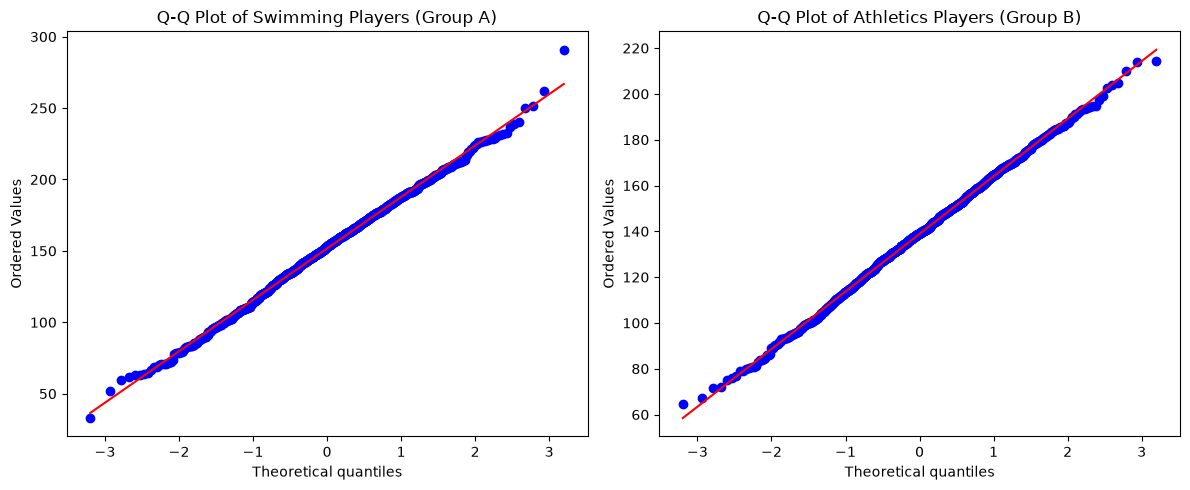

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

stats.probplot(group_a, dist="norm", plot=axes[0])
axes[0].set_title(f'Q-Q Plot of {interest_sports[0]} Players (Group A)')

stats.probplot(group_b, dist="norm", plot=axes[1])
axes[1].set_title(f'Q-Q Plot of {interest_sports[1]} Players (Group B)')

plt.tight_layout();

- Run a two-tailed **Welch's t-test** to compare the mean heights of the two groups.

In [22]:
# Your answer goes here


In [23]:
# SOLUTION: Uncomment and execute the cell below to get help
#disp(hint + '12-02-ttest-welch')

- **Is the difference large?** Compute the difference in mean height in cm. Then divide it by the average of the two standard deviations, `np.sqrt((group_a.var() + group_b.var()) / 2)`. This ratio is called **Cohen's d**; values around 0.2 are usually considered small.

In [24]:
# Your answer goes here


In [25]:
# SOLUTION: Uncomment and execute the cell below to get help
#disp(hint + '12-02-ttest-cohen')

- **Sample size, again**: repeat the sample-size analysis from Section 3 on the height data. At what sample size does this difference become significant?

In [26]:
# Your answer goes here


In [27]:
# SOLUTION: Uncomment and execute the cell below to get help
#disp(hint + '12-02-ttest-sample-size')

## Takeaways

1. **Statistical vs. practical significance.** A tiny p-value does not mean a big difference. Swimmers and athletics competitors differ by only about 1.4 cm on average, yet with thousands of athletes the p-value is far below 0.05. Always look at the size of the difference, not just the p-value.

2. **Sample size.** Larger samples make it easier to detect a real difference. They also make trivial differences significant, which is why point 1 matters.

3. **Unequal variances.** Welch's t-test (`equal_var=False`) does not assume equal variances, so it is a safe default.

4. **Normality.** Normality matters mainly for small samples. For large samples the t-test is robust to moderate non-normality; check with a histogram or Q-Q plot. If a small sample is clearly non-normal, consider the Mann-Whitney U test.

5. **Two-tailed vs. one-tailed.** A two-tailed test asks whether the groups differ at all. A one-tailed test asks about one direction, and that direction should be chosen before looking at the data.

6. **Outliers.** Outliers can pull the mean and change the result, so plot the data before testing.